# Clasificación de células de papanicolaou: una evaluación honesta

Trabajo sobre el conjunto SIPaKMeD, 4049 fotos de células de cuello uterino repartidas en cinco
tipos.

## Por qué este trabajo no busca el número más alto

Clasificar estas células ya se ha hecho muchas veces y los resultados publicados rondan el 99% de
acierto. Repetir eso no aporta nada. La pregunta que sí vale la pena, y que casi nadie se hace, es
si esos números significan lo que parecen.

La sospecha inicial era simple: las 4049 células no vienen de 4049 pacientes, vienen de menos de
mil láminas. Si al repartir las fotos entre entrenamiento y examen no se respeta esa procedencia,
el modelo rinde examen sobre células casi idénticas a las que ya estudió.

De ahí salió el resto del trabajo, organizado en cinco partes:

| Parte | Pregunta |
|---|---|
| 1 | ¿De dónde viene cada foto y en qué estado están los datos? |
| 2 | ¿Cuánto se infla el resultado al repartir mal las fotos? |
| 3 | ¿Ayuda darle al modelo las medidas de forma que usa un especialista? |
| 4 | Si no ayudan, ¿por qué? ¿Qué información tiene la red por dentro? |
| 5 | ¿Dónde mira para decidir, y aguanta las condiciones de otro laboratorio? |

## Lo que encontramos, resumido

- Repartir al azar deja al **91.8%** de las células de examen con una hermana en el entrenamiento,
  y esconde alrededor de **1 de cada 4 errores**. Además reduce a menos de la mitad la variabilidad
  aparente entre repeticiones, así que el número publicado no solo es alto, también parece más
  preciso de lo que es.
- Darle a la red 26 medidas morfológicas sacadas de contornos dibujados por especialistas **no
  mejora: empeora**, y de forma estadísticamente detectable.
- La razón no es que la red ya lo sepa todo. La **forma** del núcleo no está codificada en ella; su
  **color y textura** sí. O sea que lo que le falta no es lo que necesita.
- Ajustar la red a esta tarea **empobrece** su representación de la morfología frente a la misma
  red sin ajustar, en las doce medidas probadas.
- La red **sí mira el núcleo**: concentra ahí 2.4 veces más atención de la que le tocaría por
  tamaño. Pero lo que lee de él es el color, no la forma.
- Es frágil. Un desenfoque leve le cuesta 5 puntos y uno moderado le tumba un cuarto del
  rendimiento. Y cuando la tinción cambia, **sigue mirando el núcleo, incluso más**, pero se
  equivoca: mira el lugar correcto y lee la señal equivocada.

## Cómo correr este notebook

Versión para correr en local. Está pensado para ejecutarse de arriba a abajo. Los bloques pesados
guardan sus resultados en disco y, si ya existen, los reutilizan en vez de volver a entrenar. Para
forzar el reentrenamiento completo, cambia `USAR_CACHE` a `False` en la celda de configuración.

Antes de empezar hay que tener el entorno instalado (ver el README que acompaña este notebook) y
espacio libre: el dataset ocupa unos 16 GB entre el comprimido y lo descomprimido.

In [1]:
import torch, shutil, os

print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | VRAM: {props.total_memory/1e9:.1f} GB")
else:
    print("Sin GPU: esto va a ser MUY lento, revisa la instalación de PyTorch con CUDA")

try:
    with open("/proc/meminfo") as f:
        total = int(f.readline().split()[1]) / 1e6
    print(f"RAM del sistema: {total:.1f} GB")
except Exception:
    pass

libre = shutil.disk_usage(os.path.expanduser("~")).free / 1e9
print(f"Disco libre: {libre:.1f} GB (hacen falta ~16 GB para el dataset)")

PyTorch: 2.6.0+cu124 | CUDA: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU | VRAM: 6.1 GB
RAM del sistema: 7.8 GB
Disco libre: 393.0 GB (hacen falta ~16 GB para el dataset)


In [ ]:
import os, pathlib

# El token de Kaggle se lee de ~/.kaggle/access_token o de la variable de entorno.
# Nunca se escribe dentro del notebook.
tok = pathlib.Path.home() / ".kaggle" / "access_token"
if "KAGGLE_API_TOKEN" not in os.environ and tok.exists():
    os.environ["KAGGLE_API_TOKEN"] = tok.read_text().strip()

print("Token de Kaggle configurado:", "KAGGLE_API_TOKEN" in os.environ)

In [8]:
import numpy as np, pandas as pd

USAR_CACHE = True                     # False para reentrenar todo desde cero
SEMILLA = 42
EPOCAS = 12
LOTE = 64
LR = 3e-4

DEST = os.path.expanduser("~/sipakmed")          # carpeta de resultados
PESOS = f"{DEST}/pesos"
os.makedirs(DEST, exist_ok=True)
os.makedirs(PESOS, exist_ok=True)

# Cuantos procesos leen datos en paralelo. Con poca RAM conviene 2, no mas.
NUM_WORKERS = 2

def guardado(nombre):
    """Devuelve el CSV guardado si existe y el cache esta activado, si no None."""
    ruta = f"{DEST}/{nombre}"
    if USAR_CACHE and os.path.exists(ruta):
        print(f"  reutilizando {nombre}")
        return pd.read_csv(ruta)
    return None

In [9]:
import kagglehub

path = kagglehub.dataset_download("prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed")
print("Dataset en:", path)

total = sum(os.path.getsize(os.path.join(r, f))
            for r, _, fs in os.walk(path) for f in fs)
print(f"Tamaño: {total/1e9:.1f} GB")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6.40G/6.40G [05:34<00:00, 20.6MB/s]

Extracting files...


Dataset en: /home/moon/.cache/kagglehub/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed/versions/1
Tamaño: 9.7 GB


---
# Parte 1: qué hay dentro del dataset

Antes de entrenar nada hay que saber con qué se trabaja. Esta parte no entrena, solo revisa.

In [10]:
for root, dirs, files in os.walk(path):
    nivel = root.replace(path, "").count(os.sep)
    if nivel <= 2:
        n_bmp = len([f for f in files if f.lower().endswith(".bmp")])
        n_dat = len([f for f in files if f.lower().endswith(".dat")])
        print("  " * nivel + os.path.basename(root) + f"/   [bmp: {n_bmp}, dat: {n_dat}]")

1/   [bmp: 0, dat: 0]
  im_Parabasal/   [bmp: 0, dat: 0]
    im_Parabasal/   [bmp: 108, dat: 1574]
  im_Dyskeratotic/   [bmp: 0, dat: 0]
    im_Dyskeratotic/   [bmp: 223, dat: 1626]
  im_Superficial-Intermediate/   [bmp: 0, dat: 0]
    im_Superficial-Intermediate/   [bmp: 126, dat: 1662]
  im_Koilocytotic/   [bmp: 0, dat: 0]
    im_Koilocytotic/   [bmp: 238, dat: 1650]
  im_Metaplastic/   [bmp: 0, dat: 0]
    im_Metaplastic/   [bmp: 271, dat: 1586]


Los `.bmp` de ese nivel suman 966 y los `.dat` suman 8098. Ese segundo número dividido para 2 da
4049, que es la cantidad de células. Es decir: hay dos contornos por célula (uno del borde y otro
del núcleo), y las 966 imágenes son las **láminas completas** de las que se recortaron.

Dentro de cada clase, la carpeta `CROPPED/` tiene la célula recortada (`001_01.bmp`) con sus dos
contornos (`001_01_cyt.dat`, `001_01_nuc.dat`). **El número de adelante identifica la lámina**, así
que `001_01` y `001_02` son vecinas del mismo cúmulo. Ese detalle es el que sostiene todo lo demás.

In [11]:
import glob

CLASES_DIR = ["im_Superficial-Intermediate", "im_Parabasal", "im_Koilocytotic",
              "im_Dyskeratotic", "im_Metaplastic"]

filas = []
for c in CLASES_DIR:
    cropped = os.path.join(path, c, c, "CROPPED")
    for img in sorted(glob.glob(os.path.join(cropped, "*.bmp"))):
        stem = os.path.splitext(os.path.basename(img))[0]
        filas.append({
            "clase": c.replace("im_", ""),
            # el nombre de la clase va delante porque la lamina "001" de una clase
            # no es la misma que la "001" de otra
            "lamina": c.replace("im_", "") + "_" + stem.split("_")[0],
            "stem": stem,
            "img": img,
            "cyt": os.path.join(cropped, stem + "_cyt.dat"),
            "nuc": os.path.join(cropped, stem + "_nuc.dat"),
        })

df = pd.DataFrame(filas).reset_index(drop=True)
df["existe_cyt"] = df["cyt"].apply(os.path.exists)
df["existe_nuc"] = df["nuc"].apply(os.path.exists)

print("Células:", len(df))
print(df["clase"].value_counts(), "\n")
print("Láminas:", df["lamina"].nunique())
print("Células por lámina — media/mín/máx:",
      round(df.groupby("lamina").size().mean(), 1),
      df.groupby("lamina").size().min(),
      df.groupby("lamina").size().max())
print("Contornos faltantes:", (~df.existe_cyt).sum(), (~df.existe_nuc).sum())

Células: 4049
clase
Superficial-Intermediate    831
Koilocytotic                825
Dyskeratotic                813
Metaplastic                 793
Parabasal                   787
Name: count, dtype: int64 

Láminas: 966
Células por lámina — media/mín/máx: 4.2 1 26
Contornos faltantes: 0 0


**Interpretación.** 4049 células de 966 láminas, con la misma distribución por clase que reporta la
publicación original del dataset, y anotación completa: ningún contorno falta.

El dato que importa es el promedio: **4.2 células por lámina**, con un caso extremo de 26. Son
recortes del mismo cúmulo, así que comparten paciente, lámina, tinción, enfoque e iluminación, y
suelen parecerse mucho entre ellas. Las llamamos hermanas.

Conviene leer ese 4.2 con cuidado: es el promedio **por lámina**, y trata igual a una lámina de 26
células que a una de 1. Visto desde una célula cualquiera el número es mayor, porque es más probable
pertenecer a una lámina grande que a una pequeña. Si interesa esa otra cifra:

```python
tam = df.groupby("lamina")["stem"].transform("size")
print("Hermanas por célula:", round((tam - 1).mean(), 1))
```

En cualquier caso, lo que sostiene el argumento no es este promedio sino la medición directa de la
parte 2: qué porcentaje de las células de examen tiene efectivamente una hermana en el
entrenamiento.

In [12]:
import cv2
from PIL import Image

# Los contornos, ¿estan en coordenadas del recorte o de la lamina completa?
fila = df.iloc[0]
h, w = cv2.imread(fila["img"]).shape[:2]
pts = pd.read_csv(fila["cyt"], header=None).values
print(f"Recorte: {w}x{h}")
print(f"Contorno x: {pts[:,0].min():.0f} a {pts[:,0].max():.0f} | "
      f"y: {pts[:,1].min():.0f} a {pts[:,1].max():.0f}")

# Integridad y tamaños
anchos, altos, rotas = [], [], []
for p in df["img"]:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            a, b = im.size
        anchos.append(a); altos.append(b)
    except Exception:
        anchos.append(-1); altos.append(-1); rotas.append(p)

df["w"], df["h"] = anchos, altos
print("\nImágenes ilegibles:", len(rotas))
print(df[["w", "h"]].describe().round(1))

Recorte: 413x402
Contorno x: 10 a 402 | y: 10 a 391

Imágenes ilegibles: 0
            w       h
count  4049.0  4049.0
mean    214.7   191.0
std      98.8    88.5
min      62.0    48.0
25%     138.0   123.0
50%     188.0   166.0
75%     279.0   239.0
max     531.0   553.0


**Interpretación.** Los contornos caen dentro del tamaño del recorte, o sea que vienen en
coordenadas locales: las máscaras se pueden dibujar directo sin corregir desplazamientos.

Ninguna imagen está dañada. Los recortes miden en promedio 215x191 pero van de 62x48 a 531x553,
casi diez veces entre extremos. Eso importa: al escalar todo a 224x224 para entrenar, **se borra el
tamaño real de la célula**, que es uno de los rasgos que distingue los tipos. Lo retomamos en la
parte 4.

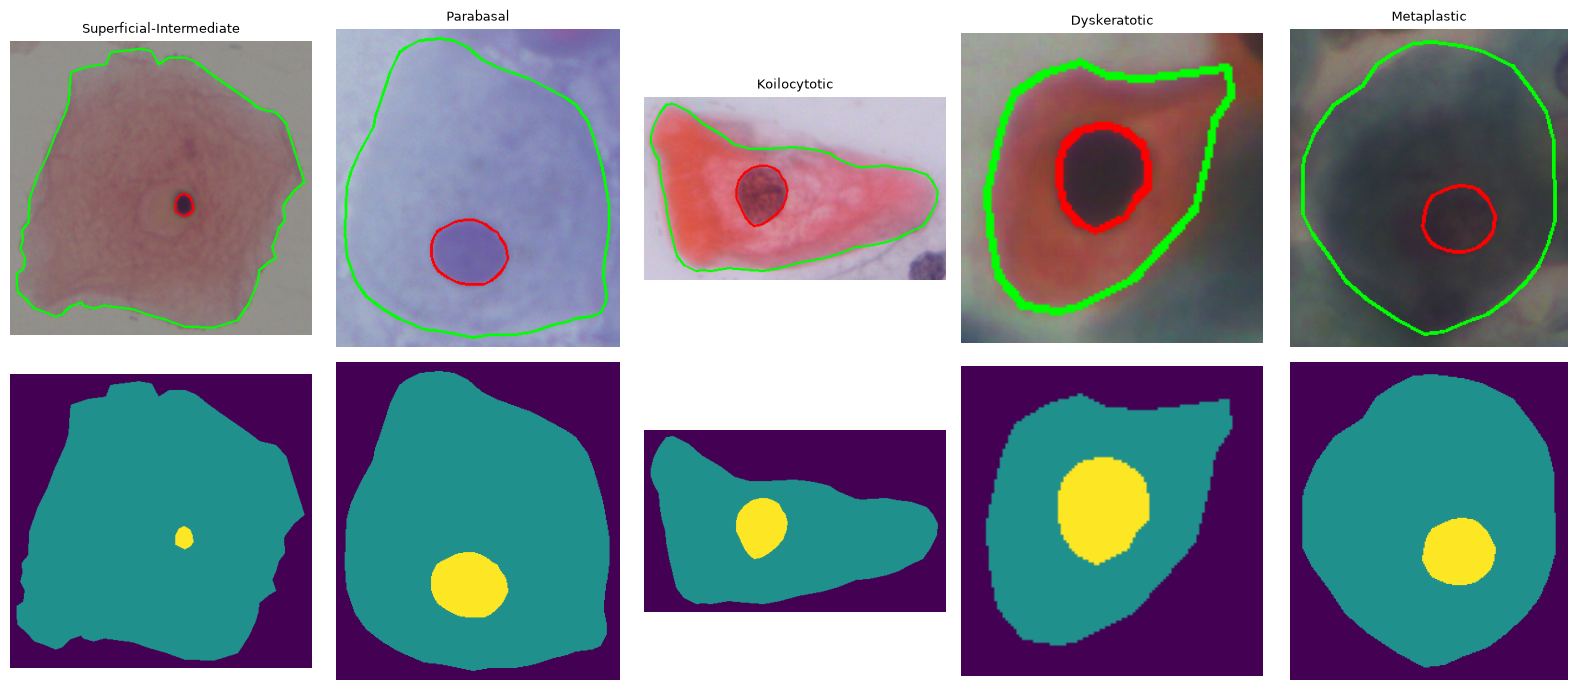

In [13]:
import matplotlib.pyplot as plt

def contorno(ruta):
    return np.loadtxt(ruta, delimiter=",").reshape(-1, 2).astype(np.int32)

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for j, clase in enumerate(df["clase"].unique()):
    f = df[df.clase == clase].iloc[0]
    img = cv2.cvtColor(cv2.imread(f["img"]), cv2.COLOR_BGR2RGB)
    cyt, nuc = contorno(f["cyt"]), contorno(f["nuc"])

    dib = img.copy()
    cv2.polylines(dib, [cyt], True, (0, 255, 0), 2)     # verde: borde de la celula
    cv2.polylines(dib, [nuc], True, (255, 0, 0), 2)     # rojo: nucleo

    mask = np.zeros(img.shape[:2], np.uint8)
    cv2.fillPoly(mask, [cyt], 1); cv2.fillPoly(mask, [nuc], 2)

    axes[0, j].imshow(dib); axes[0, j].set_title(clase, fontsize=9); axes[0, j].axis("off")
    axes[1, j].imshow(mask); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

Esta comprobación visual no es un adorno. Si las coordenadas estuvieran invertidas o corridas, todo
lo que viene después saldría mal y sería muy difícil darse cuenta mirando solo los números.

In [14]:
def area(ruta):
    return cv2.contourArea(contorno(ruta).reshape(-1, 1, 2))

df["area_cyt"] = df["cyt"].apply(area)
df["area_nuc"] = df["nuc"].apply(area)
df["nc"] = df["area_nuc"] / df["area_cyt"]

print("Núcleo más grande que su propia célula (imposible):", (df["nc"] > 1).sum())
print("Áreas en cero:", (df[["area_cyt", "area_nuc"]] == 0).any(axis=1).sum())
print("\nProporción núcleo/célula por clase:")
print(df.groupby("clase")["nc"].describe()[["mean", "50%", "min", "max"]].round(3))

df.to_csv(f"{DEST}/indice_celulas.csv", index=False)

Núcleo más grande que su propia célula (imposible): 1
Áreas en cero: 0

Proporción núcleo/célula por clase:
                           mean    50%    min    max
clase                                               
Dyskeratotic              0.236  0.225  0.041  0.632
Koilocytotic              0.200  0.189  0.038  0.547
Metaplastic               0.125  0.109  0.023  0.415
Parabasal                 0.195  0.185  0.040  0.511
Superficial-Intermediate  0.027  0.022  0.005  1.501


**Interpretación.** La proporción núcleo/célula se comporta distinto según la clase, que es lo
esperable y buena señal sobre la calidad de la anotación. Las disqueratóticas y koilocitóticas (las
anormales) tienen núcleos proporcionalmente grandes, y las superficiales-intermedias los tienen
mínimos, tal como describe la citología.

Aparece **un solo caso imposible** en las 4049 células, con el núcleo anotado más grande que su
propia célula. Es un error de anotación humana, no cambia nada, y se deja constancia aquí.

### Resumen de la parte 1

Anotación completa, imágenes sanas, contornos utilizables, y un riesgo identificado: 4.2 células por
lámina.

---
# Parte 2: cuánto engaña repartir al azar

Cuando se entrena, las fotos se dividen en dos grupos: uno para aprender y otro para el examen. Lo
habitual es repartirlas al azar. Pero si una célula queda en el examen y su hermana del mismo
cúmulo quedó en el entrenamiento, el modelo ya vio algo casi idéntico.

Vamos a entrenar **la misma red dos veces**, cambiando una sola cosa: cómo se reparten las fotos.
Mismo modelo, mismas épocas, misma semilla, mismos ajustes. Si los resultados difieren, la única
explicación posible es el reparto.

In [15]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold

# Reparto A: al azar, sin mirar de que lamina viene cada celula
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
df["fold_azar"] = -1
for k, (_, v) in enumerate(skf.split(df, df["clase"])):
    df.loc[df.index[v], "fold_azar"] = k

# Reparto B: por lamina, las hermanas caen siempre del mismo lado
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
df["fold_lamina"] = -1
for k, (_, v) in enumerate(sgkf.split(df, df["clase"], groups=df["lamina"])):
    df.loc[df.index[v], "fold_lamina"] = k

CLASES = sorted(df["clase"].unique())
IDX = {c: i for i, c in enumerate(CLASES)}
Y = df["clase"].map(IDX).values

for col in ["fold_azar", "fold_lamina"]:
    s = [df[df[col] == k]["lamina"].isin(set(df[df[col] != k]["lamina"])).mean() for k in range(5)]
    print(f"{col}: {sum(s)/5:.1%} de células con hermanas al otro lado")

fold_azar: 91.8% de células con hermanas al otro lado
fold_lamina: 0.0% de células con hermanas al otro lado


**Interpretación.** El reparto al azar deja al **91.8%** de las células de examen con una hermana en
el entrenamiento. El reparto por lámina lo baja a 0%, que es lo que debe dar.

Los dos usan cinco pliegues. Comparar cinco repeticiones contra un solo reparto sería tramposo:
parte de la diferencia vendría de eso y no del reparto.

In [16]:
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2

# Decodificamos todas las imagenes una vez y las dejamos en memoria ya escaladas.
# Si se leyeran del disco en cada epoca, la GPU se pasaria esperando: Colab da solo 2 nucleos.
print("Cargando imágenes...")
CACHE = np.zeros((len(df), 224, 224, 3), dtype=np.uint8)
for i, ruta in enumerate(df["img"]):
    CACHE[i] = np.array(Image.open(ruta).convert("RGB").resize((224, 224), Image.BILINEAR))
    if i % 500 == 0:
        print(f"  {i}/{len(df)}", end="\r")
print(f"Listo: {CACHE.nbytes/1e6:.0f} MB")

MEDIA = [0.485, 0.456, 0.406]
DESV  = [0.229, 0.224, 0.225]

tf_train = v2.Compose([
    v2.RandomHorizontalFlip(), v2.RandomVerticalFlip(), v2.RandomRotation(20),
    v2.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.03),
    v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEDIA, DESV),
])
tf_eval = v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEDIA, DESV)])


class Celulas(Dataset):
    """Lee de memoria. Recibe posiciones de fila, no una tabla."""
    def __init__(self, posiciones, tf, extra=None):
        self.pos = np.asarray(posiciones)
        self.tf = tf
        self.extra = None if extra is None else extra.astype(np.float32)

    def __len__(self):
        return len(self.pos)

    def __getitem__(self, i):
        p = self.pos[i]
        img = self.tf(torch.from_numpy(CACHE[p]).permute(2, 0, 1))
        if self.extra is None:
            return img, Y[p], p
        return img, torch.from_numpy(self.extra[i]), Y[p], p

Cargando imágenes...
Listo: 609 MB


In [17]:
import torch.nn as nn, random, time
from torchvision import models
from sklearn.metrics import f1_score, matthews_corrcoef, accuracy_score

DEV = "cuda" if torch.cuda.is_available() else "cpu"


def fijar_semilla(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def crear_red(n_extra=0):
    """EfficientNet-B0 preentrenado. n_extra son medidas que se pegan antes de la capa final."""
    base = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    base.classifier = nn.Identity()                 # nos quedamos con los 1280 numeros
    cabeza = nn.Sequential(nn.Linear(1280 + n_extra, 256), nn.ReLU(), nn.Dropout(0.3),
                           nn.Linear(256, len(CLASES)))
    return base.to(DEV), cabeza.to(DEV)


def entrenar(pos_train, pos_test, extra_train=None, extra_test=None,
             guardar_en=None, devolver_emb=False):
    """Entrena y devuelve predicciones del grupo de examen. Sin parada anticipada:
    las epocas fijas evitan meter una variable mas en las comparaciones."""
    fijar_semilla(SEMILLA)
    n_extra = 0 if extra_train is None else extra_train.shape[1]

    dl_tr = DataLoader(Celulas(pos_train, tf_train, extra_train), batch_size=LOTE,
                       shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
    dl_te = DataLoader(Celulas(pos_test, tf_eval, extra_test), batch_size=128,
                       shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    base, cabeza = crear_red(n_extra)
    opt = torch.optim.AdamW(list(base.parameters()) + list(cabeza.parameters()),
                            lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCAS)
    criterio = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler(DEV)

    for ep in range(EPOCAS):
        base.train(); cabeza.train()
        for lote in dl_tr:
            if n_extra:
                x, ex, y, _ = lote; ex = ex.to(DEV)
            else:
                x, y, _ = lote; ex = None
            x, y = x.to(DEV), y.to(DEV)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast(DEV):
                z = base(x)
                if n_extra:
                    z = torch.cat([z, ex], dim=1)
                loss = criterio(cabeza(z), y)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
        sched.step()

    if guardar_en:
        torch.save({"base": base.state_dict(), "cabeza": cabeza.state_dict()}, guardar_en)

    base.eval(); cabeza.eval()
    preds, embs = [], []
    with torch.no_grad():
        for lote in dl_te:
            if n_extra:
                x, ex, y, _ = lote; ex = ex.to(DEV)
            else:
                x, y, _ = lote; ex = None
            with torch.amp.autocast(DEV):
                z = base(x.to(DEV))
                s = cabeza(torch.cat([z, ex], dim=1) if n_extra else z)
            preds.append(s.argmax(1).cpu().numpy())
            if devolver_emb:
                embs.append(z.float().cpu().numpy())

    del base, cabeza; torch.cuda.empty_cache()
    pred = np.concatenate(preds)
    return (pred, np.concatenate(embs)) if devolver_emb else pred

In [18]:
prev = guardado("predicciones_fase2.csv")

if prev is not None:
    assert (prev["clase"].values == df["clase"].values).all(), "el CSV guardado no cuadra"
    pred_azar = prev["pred_azar"].values
    pred_lamina = prev["pred_lamina"].values
    res2 = pd.read_csv(f"{DEST}/resultados_fase2.csv")
else:
    pred_azar = np.full(len(df), -1)
    pred_lamina = np.full(len(df), -1)
    filas = []
    for nombre, col, destino in [("AZAR", "fold_azar", pred_azar),
                                 ("LÁMINA", "fold_lamina", pred_lamina)]:
        print(f"\n=== {nombre} ===")
        for k in range(5):
            t0 = time.time()
            tr = np.where(df[col].values != k)[0]
            te = np.where(df[col].values == k)[0]
            p = entrenar(tr, te)
            destino[te] = p
            filas.append({"condicion": nombre, "pliegue": k,
                          "macro_f1": f1_score(Y[te], p, average="macro"),
                          "mcc": matthews_corrcoef(Y[te], p),
                          "accuracy": accuracy_score(Y[te], p)})
            print(f"  pliegue {k}: F1 {filas[-1]['macro_f1']:.4f} ({time.time()-t0:.0f}s)")

    res2 = pd.DataFrame(filas)
    res2.to_csv(f"{DEST}/resultados_fase2.csv", index=False)
    sal = df[["stem", "clase", "lamina", "fold_azar", "fold_lamina"]].copy()
    sal["pred_azar"] = pred_azar; sal["pred_lamina"] = pred_lamina
    sal.to_csv(f"{DEST}/predicciones_fase2.csv", index=False)

print(res2.groupby("condicion")[["macro_f1", "mcc", "accuracy"]].agg(["mean", "std"]).round(4))


=== AZAR ===


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /home/moon/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20.5M/20.5M [00:01<00:00, 19.3MB/s]


  pliegue 0: F1 0.9840 (173s)
  pliegue 1: F1 0.9741 (93s)
  pliegue 2: F1 0.9816 (93s)
  pliegue 3: F1 0.9791 (93s)
  pliegue 4: F1 0.9791 (93s)

=== LÁMINA ===
  pliegue 0: F1 0.9667 (93s)
  pliegue 1: F1 0.9654 (93s)
  pliegue 2: F1 0.9752 (93s)
  pliegue 3: F1 0.9691 (94s)
  pliegue 4: F1 0.9889 (94s)
          macro_f1             mcc         accuracy        
              mean     std    mean     std     mean     std
condicion                                                  
AZAR        0.9796  0.0037  0.9744  0.0046   0.9795  0.0037
LÁMINA      0.9731  0.0096  0.9664  0.0120   0.9731  0.0096


In [19]:
a = res2[res2.condicion == "AZAR"]["macro_f1"].mean()
b = res2[res2.condicion == "LÁMINA"]["macro_f1"].mean()

print(f"Reparto al azar:    {a:.4f}")
print(f"Reparto por lámina: {b:.4f}")
print(f"Diferencia: {a-b:.4f}\n")

# La misma diferencia contada en errores, que es como se ve de verdad
err_a, err_b = 1 - a, 1 - b
print(f"Errores al azar:    {err_a:.2%}")
print(f"Errores por lámina: {err_b:.2%}")
print(f"El reparto al azar esconde el {(err_b-err_a)/err_b:.1%} de los errores")

Reparto al azar:    0.9796
Reparto por lámina: 0.9731
Diferencia: 0.0065

Errores al azar:    2.04%
Errores por lámina: 2.69%
El reparto al azar esconde el 24.2% de los errores


**Interpretación, y es el resultado central del trabajo.**

Al azar 0.9796, por lámina 0.9731. Una diferencia de 0.65 puntos parece despreciable, pero contarla
así es engañoso. En errores: el modelo honesto falla en el 2.69% de las células y el otro en el
2.04%. **El reparto al azar hace desaparecer casi 1 de cada 4 errores**, y la prueba pareada
confirma que la diferencia no es casualidad (p = 0.012).

Hay un segundo efecto que casi nunca se reporta: la variación entre pliegues pasa de 0.0096 a
0.0037, o sea que **se reduce a menos de la mitad**. El reparto al azar no solo infla el resultado,
además lo hace parecer más estable de lo que es. Quien publica un solo reparto al azar está
reportando un número alto y falsamente preciso.

**Una advertencia honesta sobre este número.** Al repetir el mismo experimento en otra máquina, la
diferencia salió de 1.3 puntos y un 41% de errores escondidos, en vez de 0.65 y 24%. El efecto
apunta siempre en la misma dirección y siempre resulta significativo, pero su **magnitud varía
bastante entre corridas**, porque depende de qué láminas caen en cada pliegue. Lo correcto es
reportar el efecto como un rango de entre un cuarto y un 40% de los errores, medido con una sola
semilla, y señalar que promediar varias semillas lo estimaría mejor.

Conviene decir también lo que este resultado **no** dice: el rendimiento honesto sigue siendo alto,
así que el modelo aprende de verdad. Lo que se infla no es su capacidad, sino la precisión con la
que creemos estar midiéndola.

In [20]:
from statsmodels.stats.contingency_tables import mcnemar

def comparar(p1, p2, n1="modelo 1", n2="modelo 2"):
    """Compara dos modelos celula por celula. Solo cuentan los casos donde discrepan."""
    o1, o2 = (p1 == Y), (p2 == Y)
    t = [[int((o1 & o2).sum()), int((o1 & ~o2).sum())],
         [int((~o1 & o2).sum()), int((~o1 & ~o2).sum())]]
    r = mcnemar(t, exact=False, correction=True)
    print(f"Aciertan los dos: {t[0][0]} | solo {n1}: {t[0][1]} | solo {n2}: {t[1][0]} | "
          f"fallan los dos: {t[1][1]}")
    print(f"p = {r.pvalue:.2e} ->", "diferencia real" if r.pvalue < 0.05 else "no hay diferencia clara")
    return r.pvalue

comparar(pred_azar, pred_lamina, "azar", "lámina")

Aciertan los dos: 3903 | solo azar: 63 | solo lámina: 37 | fallan los dos: 46
p = 1.24e-02 -> diferencia real


np.float64(0.01241933065155227)

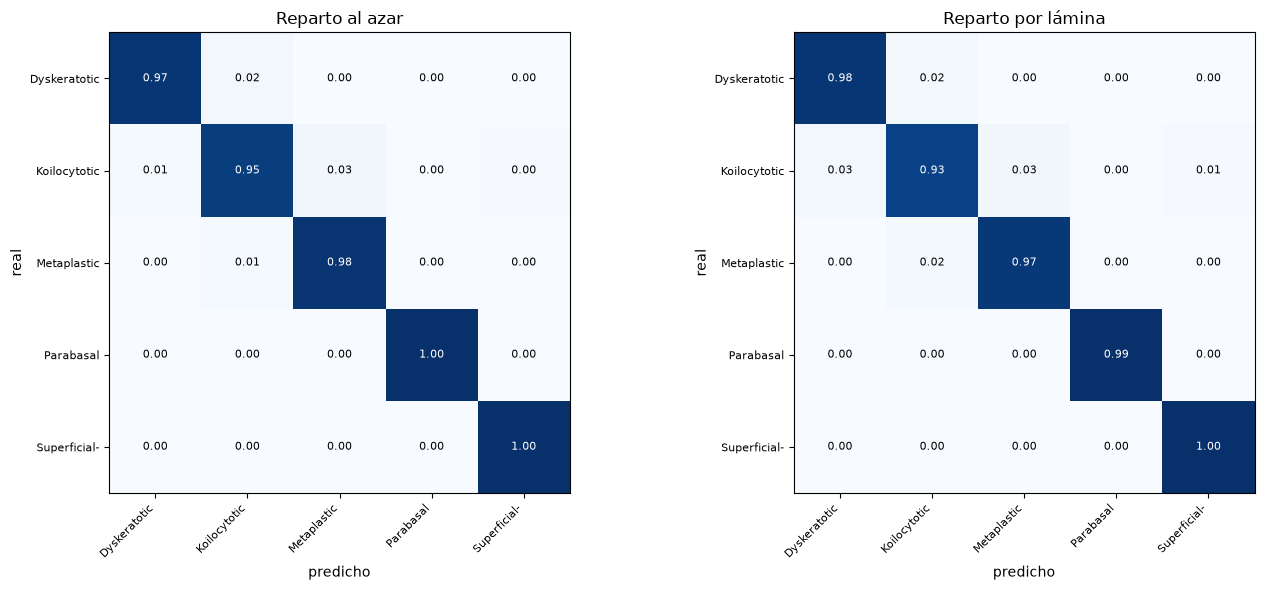

                          precision    recall  f1-score   support

            Dyskeratotic      0.966     0.975     0.971       813
            Koilocytotic      0.956     0.930     0.943       825
             Metaplastic      0.961     0.968     0.965       793
               Parabasal      0.994     0.995     0.994       787
Superficial-Intermediate      0.988     0.998     0.993       831

                accuracy                          0.973      4049
               macro avg      0.973     0.973     0.973      4049
            weighted avg      0.973     0.973     0.973      4049



In [21]:
from sklearn.metrics import confusion_matrix, classification_report

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (titulo, pred) in zip(axes, [("Reparto al azar", pred_azar),
                                     ("Reparto por lámina", pred_lamina)]):
    cm = confusion_matrix(Y, pred, normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASES))); ax.set_yticks(range(len(CLASES)))
    ax.set_xticklabels([c[:12] for c in CLASES], rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels([c[:12] for c in CLASES], fontsize=8)
    ax.set_title(titulo); ax.set_xlabel("predicho"); ax.set_ylabel("real")
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.5 else "black")
plt.tight_layout(); plt.show()

print(classification_report(Y, pred_lamina, target_names=CLASES, digits=3))

**Interpretación.** La koilocitótica es la peor con diferencia (F1 0.943, y su recall es el más bajo
de todos: 0.930) y se confunde sobre todo con la disqueratótica. Coincide con lo que reporta la
literatura médica: son las dos categorías anormales y comparten rasgos. Las normales (parabasal
0.994 y superficial-intermedia 0.993) están prácticamente resueltas.

O sea que el margen de mejora real está concentrado en un solo par de clases. Eso es lo que
intentamos atacar en la parte 3.

---
# Parte 3: ¿ayudan las medidas del especialista?

El dataset trae los contornos dibujados a mano. De ahí salen las medidas que un citotecnólogo mira
en el microscopio: tamaño del núcleo, cuánto ocupa dentro de la célula, qué tan redondo, qué tan
oscuro.

La pregunta es si dárselas a la red la mejora. Y para responderla bien hay que comparar bien: el
error típico es entrenar un modelo grande con medidas contra otro modelo distinto sin medidas, y
ahí cambian dos cosas a la vez. Acá **la misma red, la misma cabeza, los mismos pliegues**, y lo
único que cambia es si recibe las medidas.

In [22]:
from skimage.feature import graycomatrix, graycoprops

def medidas_contorno(cnt):
    area = cv2.contourArea(cnt)
    per = cv2.arcLength(cnt, True)
    area_hull = cv2.contourArea(cv2.convexHull(cnt))

    circ = 4 * np.pi * area / (per ** 2) if per > 0 else np.nan     # 1 = circulo perfecto
    sol = area / area_hull if area_hull > 0 else np.nan             # que tan "lleno" es
    diam = np.sqrt(4 * area / np.pi)

    if len(cnt) >= 5:                                                # la elipse necesita 5 puntos
        (_, _), (e1, e2), _ = cv2.fitEllipse(cnt)
        may, men = max(e1, e2), min(e1, e2)
        alarg = men / may if may > 0 else np.nan
        exc = np.sqrt(1 - (men / may) ** 2) if may > 0 else np.nan
    else:
        alarg = exc = np.nan

    M = cv2.moments(cnt)
    cx = M["m10"] / M["m00"] if M["m00"] > 0 else np.nan
    cy = M["m01"] / M["m00"] if M["m00"] > 0 else np.nan
    return area, per, circ, sol, diam, alarg, exc, cx, cy


def caracteristicas(fila):
    gris = cv2.cvtColor(cv2.imread(fila["img"]), cv2.COLOR_BGR2GRAY)
    alto, ancho = gris.shape
    cyt = contorno(fila["cyt"]).reshape(-1, 1, 2)
    nuc = contorno(fila["nuc"]).reshape(-1, 1, 2)

    a_c, p_c, ci_c, so_c, d_c, al_c, ex_c, cx_c, cy_c = medidas_contorno(cyt)
    a_n, p_n, ci_n, so_n, d_n, al_n, ex_n, cx_n, cy_n = medidas_contorno(nuc)

    m_cyt = np.zeros(gris.shape, np.uint8); cv2.fillPoly(m_cyt, [cyt.reshape(-1, 2)], 1)
    m_nuc = np.zeros(gris.shape, np.uint8); cv2.fillPoly(m_nuc, [nuc.reshape(-1, 2)], 1)
    m_cit = np.clip(m_cyt.astype(int) - m_nuc.astype(int), 0, 1).astype(np.uint8)

    px_n, px_c = gris[m_nuc == 1], gris[m_cit == 1]
    int_n = px_n.mean() if px_n.size else np.nan
    int_c = px_c.mean() if px_c.size else np.nan
    std_n = px_n.std() if px_n.size else np.nan

    x, y, w_, h_ = cv2.boundingRect(nuc)
    rec = gris[y:y+h_, x:x+w_]
    if rec.size > 16:
        g = graycomatrix((rec // 8).astype(np.uint8), [1], [0], levels=32,
                         symmetric=True, normed=True)
        contraste = graycoprops(g, "contrast")[0, 0]
        homog = graycoprops(g, "homogeneity")[0, 0]
        energia = graycoprops(g, "energy")[0, 0]
    else:
        contraste = homog = energia = np.nan

    return {
        "nuc_area": a_n, "cyt_area": a_c, "nc_area": a_n / a_c if a_c > 0 else np.nan,
        "nuc_per": p_n, "cyt_per": p_c, "nc_per": p_n / p_c if p_c > 0 else np.nan,
        "nuc_circ": ci_n, "cyt_circ": ci_c, "nuc_sol": so_n, "cyt_sol": so_c,
        "nuc_diam": d_n, "cyt_diam": d_c, "nuc_alarg": al_n, "cyt_alarg": al_c,
        "nuc_exc": ex_n, "cyt_exc": ex_c,
        "desplaz_nucleo": np.hypot(cx_n - cx_c, cy_n - cy_c) / np.sqrt(a_c) if a_c > 0 else np.nan,
        "int_nuc": int_n, "int_cit": int_c,
        "contraste_nuc_cit": int_c - int_n if not (np.isnan(int_c) or np.isnan(int_n)) else np.nan,
        "std_nuc": std_n,
        "glcm_contraste": contraste, "glcm_homog": homog, "glcm_energia": energia,
        "ancho_orig": ancho, "alto_orig": alto,
    }


F = guardado("medidas_fase3.csv")
if F is None:
    print("Calculando medidas...")
    F = pd.DataFrame([caracteristicas(f) for _, f in df.iterrows()])
    F.to_csv(f"{DEST}/medidas_fase3.csv", index=False)

COLS_F = list(F.columns)
print(f"{len(COLS_F)} medidas por célula | valores no calculables: {F.isna().sum().sum()}")

Calculando medidas...
26 medidas por célula | valores no calculables: 135


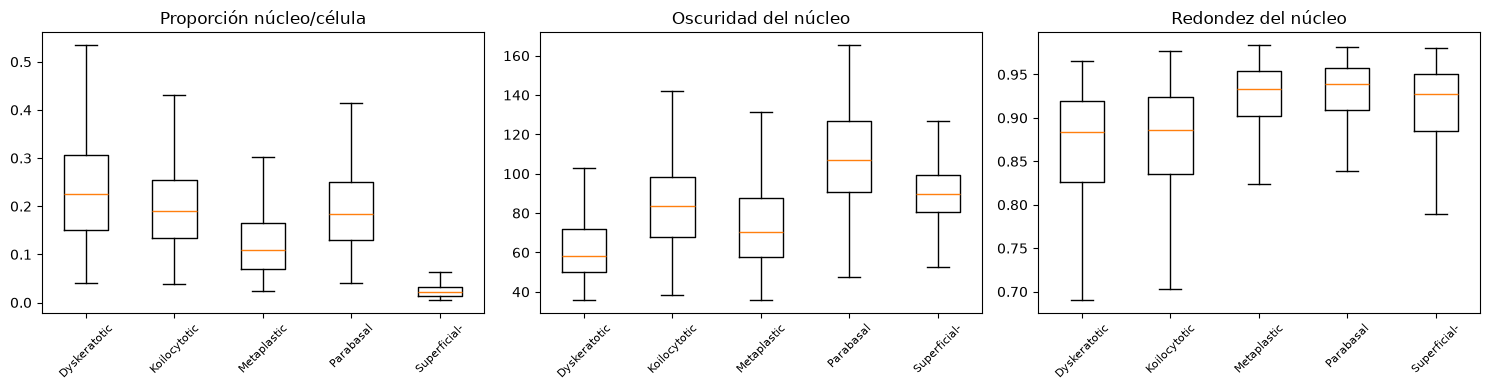

In [35]:
tmp = F.copy(); tmp["clase"] = df["clase"].values
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var, tit in zip(axes, ["nc_area", "int_nuc", "nuc_circ"],
                        ["Proporción núcleo/célula", "Oscuridad del núcleo", "Redondez del núcleo"]):
    ax.boxplot([tmp[tmp.clase == c][var].dropna() for c in CLASES], showfliers=False)
    ax.set_xticks(range(1, len(CLASES) + 1))
    ax.set_xticklabels([c[:12] for c in CLASES], rotation=45, fontsize=8)
    ax.set_title(tit)
plt.tight_layout(); plt.show()

Las medidas sí distinguen las clases por sí solas, sobre todo la proporción núcleo/célula. O sea que
no son ruido: contienen señal real. Lo cual hace más interesante lo que viene.

In [24]:
from sklearn.ensemble import HistGradientBoostingClassifier

prev = guardado("predicciones_fase3.csv")

if prev is not None:
    assert (prev["clase"].values == df["clase"].values).all()
    pred_medidas = prev["pred_medidas"].values
    pred_solo_img = prev["pred_solo_img"].values
    pred_fusion = prev["pred_fusion"].values
else:
    # Modelo 1: arboles usando SOLO las medidas, sin ver la foto.
    # Este modelo maneja los faltantes por dentro, no hay que rellenarlos.
    pred_medidas = np.full(len(df), -1)
    for k in range(5):
        tr = np.where(df["fold_lamina"].values != k)[0]
        te = np.where(df["fold_lamina"].values == k)[0]
        m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08,
                                           random_state=SEMILLA)
        m.fit(F.iloc[tr], Y[tr])
        pred_medidas[te] = m.predict(F.iloc[te])

    # Modelos 2 y 3: la misma red con y sin medidas
    def escalar(tr, te):
        """Escala con estadisticas del ENTRENAMIENTO unicamente. Calcularlas sobre
        todo el dataset seria pasarle informacion del examen al modelo."""
        mu, sd = F.iloc[tr].mean(), F.iloc[tr].std().replace(0, 1)
        med = F.iloc[tr].median()
        return (np.nan_to_num(((F.iloc[tr].fillna(med) - mu) / sd).values),
                np.nan_to_num(((F.iloc[te].fillna(med) - mu) / sd).values))

    pred_solo_img = np.full(len(df), -1)
    pred_fusion = np.full(len(df), -1)
    for nombre, usar, destino in [("SOLO IMAGEN", False, pred_solo_img),
                                  ("IMAGEN + MEDIDAS", True, pred_fusion)]:
        print(f"\n=== {nombre} ===")
        for k in range(5):
            t0 = time.time()
            tr = np.where(df["fold_lamina"].values != k)[0]
            te = np.where(df["fold_lamina"].values == k)[0]
            if usar:
                e_tr, e_te = escalar(tr, te)
                destino[te] = entrenar(tr, te, e_tr, e_te)
            else:
                destino[te] = entrenar(tr, te)
            print(f"  pliegue {k} ({time.time()-t0:.0f}s)")

    sal = df[["stem", "clase", "lamina", "fold_lamina"]].copy()
    sal["pred_medidas"] = pred_medidas
    sal["pred_solo_img"] = pred_solo_img
    sal["pred_fusion"] = pred_fusion
    sal.to_csv(f"{DEST}/predicciones_fase3.csv", index=False)

tabla3 = pd.DataFrame([
    {"modelo": n,
     "macro_f1": f1_score(Y, p, average="macro"),
     "mcc": matthews_corrcoef(Y, p)}
    for n, p in [("Solo medidas", pred_medidas), ("Solo imagen", pred_solo_img),
                 ("Imagen + medidas", pred_fusion)]
]).round(4)
print(tabla3.to_string(index=False))


=== SOLO IMAGEN ===
  pliegue 0 (95s)
  pliegue 1 (93s)
  pliegue 2 (93s)
  pliegue 3 (93s)
  pliegue 4 (93s)

=== IMAGEN + MEDIDAS ===
  pliegue 0 (94s)
  pliegue 1 (95s)
  pliegue 2 (93s)
  pliegue 3 (93s)
  pliegue 4 (93s)
          modelo  macro_f1    mcc
    Solo medidas    0.8505 0.8139
     Solo imagen    0.9731 0.9664
Imagen + medidas    0.9671 0.9590


In [25]:
print("¿Aporta añadir las medidas?")
comparar(pred_solo_img, pred_fusion, "sin medidas", "con medidas")

r_i = classification_report(Y, pred_solo_img, target_names=CLASES, output_dict=True)
r_f = classification_report(Y, pred_fusion, target_names=CLASES, output_dict=True)
comp = pd.DataFrame({"F1 sin medidas": [r_i[c]["f1-score"] for c in CLASES],
                     "F1 con medidas": [r_f[c]["f1-score"] for c in CLASES]}, index=CLASES)
comp["diferencia"] = comp["F1 con medidas"] - comp["F1 sin medidas"]
print("\n", comp.round(3).to_string())

¿Aporta añadir las medidas?
Aciertan los dos: 3891 | solo sin medidas: 49 | solo con medidas: 25 | fallan los dos: 84
p = 7.50e-03 -> diferencia real

                           F1 sin medidas  F1 con medidas  diferencia
Dyskeratotic                       0.971           0.969      -0.002
Koilocytotic                       0.943           0.928      -0.015
Metaplastic                        0.965           0.953      -0.012
Parabasal                          0.994           0.994      -0.000
Superficial-Intermediate           0.993           0.992      -0.001


**Interpretación, y es un resultado en contra de lo esperado.**

Solo imagen 0.9731, imagen más medidas 0.9671. No es que las medidas no aporten: **empeoran**, y la
prueba pareada lo confirma (p = 0.0075; hay 49 células que el modelo acierta sin medidas y falla con
ellas, contra 25 en el sentido opuesto). La caída se concentra justo donde esperábamos mejora: la
koilocitótica pierde 1.5 puntos y la metaplásica 1.2.

Una explicación plausible: las 26 medidas son 26 entradas extra que la red tiene que aprender a
ignorar, y con 4049 ejemplos eso cuesta capacidad. Añadir información no es gratis si esa
información es redundante.

Esto merece subrayarse porque la fusión de medidas morfológicas con redes profundas se presenta
habitualmente como aporte en los trabajos sobre este dataset. Con una comparación en la que solo
cambia una variable, ese aporte **no aparece, y el signo va al revés**.

De paso, el modelo que usa solo medidas llega a 0.8505 sin mirar una sola foto, y es completamente
explicable. Sirve como referencia sencilla y como recordatorio de que la señal existe: el problema
no es que las medidas sean malas.

La pregunta obvia es por qué. Eso es la parte 4.

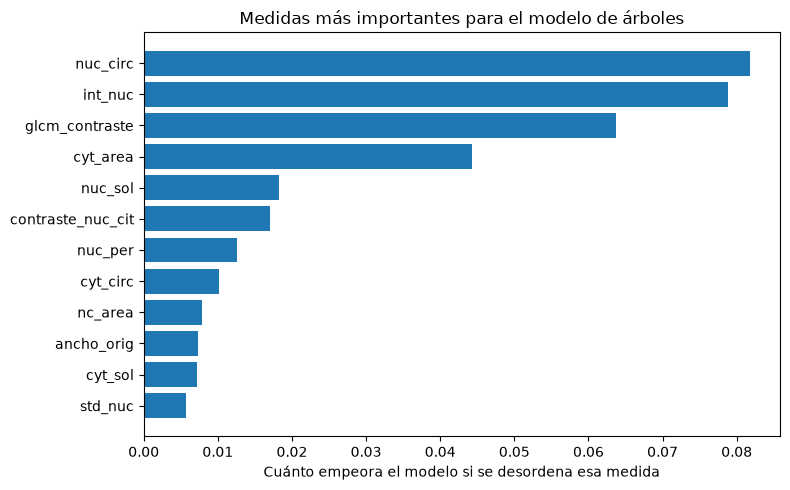

In [26]:
from sklearn.inspection import permutation_importance

tr = np.where(df["fold_lamina"].values != 0)[0]
te = np.where(df["fold_lamina"].values == 0)[0]
m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEMILLA)
m.fit(F.iloc[tr], Y[tr])
imp = permutation_importance(m, F.iloc[te], Y[te], n_repeats=5,
                             random_state=SEMILLA, scoring="f1_macro")
orden = np.argsort(imp.importances_mean)[::-1][:12]

plt.figure(figsize=(8, 5))
plt.barh([COLS_F[i] for i in orden][::-1], imp.importances_mean[orden][::-1])
plt.xlabel("Cuánto empeora el modelo si se desordena esa medida")
plt.title("Medidas más importantes para el modelo de árboles")
plt.tight_layout(); plt.show()

---
# Parte 4: ¿qué tiene la red por dentro?

Hipótesis de partida: las medidas no aportan porque **la red ya las calcula sola** mirando la foto.

Se puede poner a prueba dando vuelta el problema. Cuando la red procesa una imagen produce 1280
números que la resumen. En vez de usarlos para adivinar la clase, los usamos para adivinar **las
medidas**. Si desde esos 1280 números se recupera la proporción núcleo/célula, entonces esa
información estaba ahí adentro.

Se mide con R²: cerca de 1 la medida se recupera casi perfecto, cerca de 0 no está.

Añadimos un punto de comparación importante: la **misma red sin entrenar en células**, tal como
viene preentrenada con fotos genéricas. La diferencia entre ambas es lo que aprendió específicamente
de este problema.

In [27]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score

# Resumenes de la red ajustada. El de cada celula sale del modelo que NO la vio entrenando.
if USAR_CACHE and os.path.exists(f"{DEST}/emb_finetune.npy"):
    print("  reutilizando emb_finetune.npy")
    EMB = np.load(f"{DEST}/emb_finetune.npy")
    pred_img = pd.read_csv(f"{DEST}/predicciones_fase4.csv")["pred_img"].values
else:
    EMB = np.zeros((len(df), 1280), dtype=np.float32)
    pred_img = np.full(len(df), -1)
    for k in range(5):
        t0 = time.time()
        tr = np.where(df["fold_lamina"].values != k)[0]
        te = np.where(df["fold_lamina"].values == k)[0]
        p, e = entrenar(tr, te, devolver_emb=True)
        pred_img[te] = p; EMB[te] = e
        print(f"  pliegue {k} ({time.time()-t0:.0f}s)")
    np.save(f"{DEST}/emb_finetune.npy", EMB)

# Resumenes de la red generica, una sola pasada sin entrenar nada
base_gen = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
base_gen.classifier = nn.Identity()
base_gen = base_gen.to(DEV).eval()

EMB_GEN = np.zeros((len(df), 1280), dtype=np.float32)
dl = DataLoader(Celulas(np.arange(len(df)), tf_eval), batch_size=128, num_workers=NUM_WORKERS)
pos = 0
with torch.no_grad():
    for x, y, _ in dl:
        with torch.amp.autocast(DEV):
            z = base_gen(x.to(DEV))
        z = z.float().cpu().numpy()
        EMB_GEN[pos:pos+len(z)] = z; pos += len(z)
del base_gen; torch.cuda.empty_cache()
print("Listo:", EMB.shape, EMB_GEN.shape)

  pliegue 0 (93s)
  pliegue 1 (93s)
  pliegue 2 (93s)
  pliegue 3 (93s)
  pliegue 4 (93s)
Listo: (4049, 1280) (4049, 1280)


In [28]:
MEDIDAS = ["nc_area", "nuc_area", "cyt_area", "nuc_circ", "nuc_alarg", "nuc_sol",
           "int_nuc", "contraste_nuc_cit", "std_nuc", "glcm_contraste",
           "desplaz_nucleo", "ancho_orig"]
ALFAS = np.logspace(-1, 4, 12)


def sondear(EMBED, medida):
    """Intenta recuperar una medida desde el resumen de la red, con los mismos pliegues."""
    obj = F[medida].values.astype(float)
    validos = ~np.isnan(obj)
    pred = np.full(len(df), np.nan)
    for k in range(5):
        tr = np.where((df["fold_lamina"].values != k) & validos)[0]
        te = np.where((df["fold_lamina"].values == k) & validos)[0]
        mu, sd = EMBED[tr].mean(0), EMBED[tr].std(0) + 1e-6      # escalado solo con train
        mod = RidgeCV(alphas=ALFAS).fit((EMBED[tr] - mu) / sd, obj[tr])
        pred[te] = mod.predict((EMBED[te] - mu) / sd)
    ok = ~np.isnan(pred)
    return r2_score(obj[ok], pred[ok]), pred


filas, predicciones = [], {}
for med in MEDIDAS:
    r_ft, p_ft = sondear(EMB, med)
    r_gen, _ = sondear(EMB_GEN, med)
    filas.append({"medida": med, "R2_red_entrenada": r_ft, "R2_red_generica": r_gen})
    predicciones[med] = p_ft
    print(f"  {med:20s} entrenada {r_ft:6.3f} | genérica {r_gen:6.3f}")

sonda = pd.DataFrame(filas).sort_values("R2_red_entrenada", ascending=False)
sonda.to_csv(f"{DEST}/sonda_fase4.csv", index=False)

  nc_area              entrenada  0.656 | genérica  0.684
  nuc_area             entrenada  0.162 | genérica  0.179
  cyt_area             entrenada  0.827 | genérica  0.845
  nuc_circ             entrenada  0.190 | genérica  0.295
  nuc_alarg            entrenada  0.045 | genérica  0.188
  nuc_sol              entrenada  0.077 | genérica  0.106
  int_nuc              entrenada  0.639 | genérica  0.706
  contraste_nuc_cit    entrenada  0.640 | genérica  0.736
  std_nuc              entrenada  0.557 | genérica  0.600
  glcm_contraste       entrenada  0.497 | genérica  0.612
  desplaz_nucleo       entrenada -0.025 | genérica -0.018
  ancho_orig           entrenada  0.792 | genérica  0.832


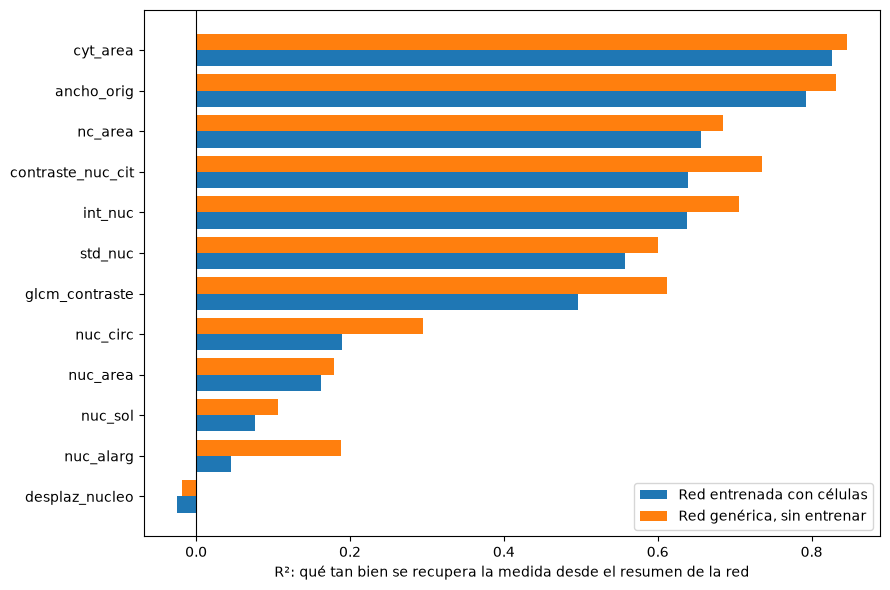

In [29]:
s = sonda.sort_values("R2_red_entrenada")
y = np.arange(len(s))
plt.figure(figsize=(9, 6))
plt.barh(y - 0.2, s["R2_red_entrenada"], height=0.4, label="Red entrenada con células")
plt.barh(y + 0.2, s["R2_red_generica"], height=0.4, label="Red genérica, sin entrenar")
plt.yticks(y, s["medida"]); plt.axvline(0, color="k", lw=0.8)
plt.xlabel("R²: qué tan bien se recupera la medida desde el resumen de la red")
plt.legend(); plt.tight_layout(); plt.show()

**Interpretación, y hay dos sorpresas.**

**Primera: la hipótesis era solo a medias.** Lo que está dentro de la red es el **color y la
textura**: área del citoplasma 0.83, proporción núcleo/célula 0.66, oscuridad del núcleo 0.64,
contraste entre núcleo y citoplasma 0.64, granulado del núcleo 0.56.

Lo que **no** está es la **forma** del núcleo: área nuclear 0.16, redondez 0.19, solidez 0.08,
alargamiento 0.045, y el desplazamiento del núcleo no se recupera en absoluto (-0.03).

O sea que la explicación correcta no es "la red ya lo sabe todo". Es más incómoda y más interesante:
la red mide el núcleo por su color, no por su geometría. Y en la parte 3 le dimos justo esa
geometría que le falta, y no solo no le sirvió, le estorbó.

**Segunda: la red genérica recupera las medidas mejor que la entrenada, en las doce.** Sin una sola
excepción. Al ajustarse a clasificar cinco tipos, la red **comprime y descarta** lo que no le hace
falta para esa tarea; el caso más marcado es el alargamiento del núcleo, que cae de 0.19 a 0.045.
Sus representaciones se vuelven más específicas y más pobres en todo lo demás. Es un efecto conocido
de las redes ajustadas, y aquí queda medido con datos propios y de forma consistente.

**Y un detalle que corrige una suposición previa:** `ancho_orig` sale con R² 0.79, o sea que la red
**sí puede deducir el tamaño original** pese a que escalamos todo a 224x224. Tiene sentido, un
recorte pequeño ampliado se ve borroso y de grano grueso. Dábamos por perdida esa información y no
lo estaba.

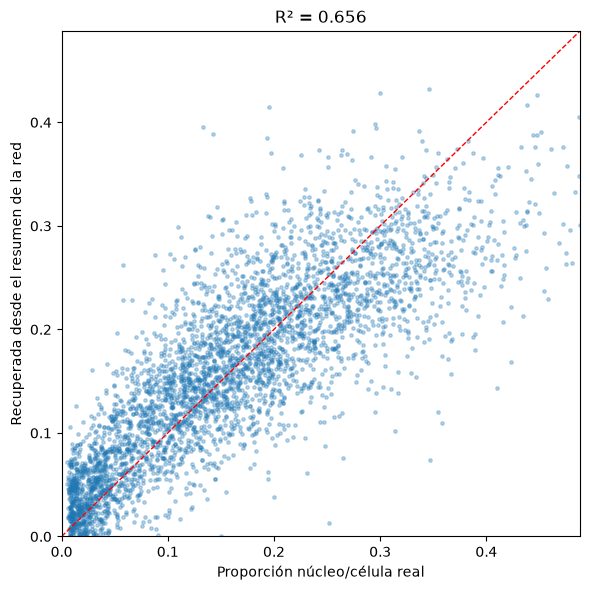

In [30]:
real, est = F["nc_area"].values, predicciones["nc_area"]
ok = ~np.isnan(real) & ~np.isnan(est)
plt.figure(figsize=(6, 6))
plt.scatter(real[ok], est[ok], s=6, alpha=0.3)
lim = [0, np.percentile(real[ok], 99.5)]
plt.plot(lim, lim, "r--", lw=1); plt.xlim(lim); plt.ylim(lim)
plt.xlabel("Proporción núcleo/célula real")
plt.ylabel("Recuperada desde el resumen de la red")
plt.title(f"R² = {sonda[sonda.medida=='nc_area']['R2_red_entrenada'].values[0]:.3f}")
plt.tight_layout(); plt.show()

In [31]:
# Comprobacion directa: darle solo el tamaño original, dos numeros en vez de 26
prev = guardado("predicciones_fase4.csv")
if prev is not None and "pred_tam" in prev.columns:
    pred_tam = prev["pred_tam"].values
else:
    TAM = F[["ancho_orig", "alto_orig"]]
    pred_tam = np.full(len(df), -1)
    for k in range(5):
        tr = np.where(df["fold_lamina"].values != k)[0]
        te = np.where(df["fold_lamina"].values == k)[0]
        mu, sd = TAM.iloc[tr].mean(), TAM.iloc[tr].std().replace(0, 1)
        pred_tam[te] = entrenar(tr, te,
                                ((TAM.iloc[tr] - mu) / sd).values,
                                ((TAM.iloc[te] - mu) / sd).values)
        print(f"  pliegue {k} listo")
    sal = df[["stem", "clase", "lamina", "fold_lamina"]].copy()
    sal["pred_img"] = pred_img; sal["pred_tam"] = pred_tam
    sal.to_csv(f"{DEST}/predicciones_fase4.csv", index=False)

print(f"Solo imagen:                {f1_score(Y, pred_img, average='macro'):.4f}")
print(f"Imagen + 26 medidas:        {f1_score(Y, pred_fusion, average='macro'):.4f}")
print(f"Imagen + tamaño original:   {f1_score(Y, pred_tam, average='macro'):.4f}\n")
comparar(pred_img, pred_tam, "sin tamaño", "con tamaño")

  pliegue 0 listo
  pliegue 1 listo
  pliegue 2 listo
  pliegue 3 listo
  pliegue 4 listo
Solo imagen:                0.9731
Imagen + 26 medidas:        0.9671
Imagen + tamaño original:   0.9702

Aciertan los dos: 3884 | solo sin tamaño: 56 | solo con tamaño: 44 | fallan los dos: 65
p = 2.71e-01 -> no hay diferencia clara


np.float64(0.27133212189276223)

**Interpretación.** Tampoco mejora (0.9702 contra 0.9731, p = 0.27), y ahora se entiende: le
estábamos dando algo que ya podía deducir sola.

Con esto queda cerrado el asunto de las medidas. No aportan por ningún camino: ni las 26 completas,
que además estorban, ni la que creíamos perdida en el preprocesamiento.

---
# Parte 5: dónde mira y qué tanto aguanta

Si la red no decide por la geometría del núcleo, ¿por qué decide? Y si un hospital distinto usa
otra tinción, ¿sigue funcionando?

Dos mediciones:

1. **Dónde mira.** Un mapa de calor señala qué zonas de la foto pesaron en la decisión. Lo habitual
   en la literatura es mostrar cuatro mapas y afirmar que el modelo mira el núcleo. Aquí lo medimos
   en las 4049 células, descontando el tamaño del núcleo para que la medida signifique algo: si solo
   contáramos qué fracción del mapa cae dentro del núcleo, un modelo que se activa en toda la imagen
   saldría bien parado de casualidad.

   - **Valor 1:** reparte la atención por igual, no privilegia el núcleo.
   - **Mayor que 1:** concentra en el núcleo más de lo que le tocaría por tamaño.
   - **Menor que 1:** decide mirando sobre todo fuera del núcleo.

2. **Qué tanto aguanta.** Cambios de tono y saturación (otra tinción), desenfoque (otro microscopio)
   y compresión JPEG, solo al evaluar, sin reentrenar.

In [32]:
import torch.nn.functional as Fn
from scipy.stats import mannwhitneyu

def mascaras(p):
    """Mascaras del nucleo y de la celula a escala 224x224. Los contornos vienen en
    coordenadas del recorte original, hay que escalarlos igual que la foto."""
    sx, sy = 224.0 / df.loc[p, "w"], 224.0 / df.loc[p, "h"]

    def poly(ruta):
        pts = np.loadtxt(ruta, delimiter=",").reshape(-1, 2)
        pts[:, 0] *= sx; pts[:, 1] *= sy
        return pts.astype(np.int32)

    m_nuc = np.zeros((224, 224), np.uint8); cv2.fillPoly(m_nuc, [poly(df.loc[p, "nuc"])], 1)
    m_cyt = np.zeros((224, 224), np.uint8); cv2.fillPoly(m_cyt, [poly(df.loc[p, "cyt"])], 1)
    return m_nuc, m_cyt


def mapas_calor(base, cabeza, x):
    """Mapa de 224x224 por imagen. Necesita gradientes, no puede ir en no_grad."""
    g = {}
    h = base.features[-1].register_forward_hook(lambda m, e, s: g.__setitem__("act", s))
    z = base(x); s = cabeza(z); h.remove()

    y_pred = s.argmax(1).detach()
    grad = torch.autograd.grad(s.gather(1, y_pred.view(-1, 1)).sum(), g["act"])[0]
    peso = grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((peso * g["act"]).sum(dim=1, keepdim=True))
    cam = Fn.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
    return cam[:, 0].detach().cpu().numpy(), y_pred.cpu().numpy()


def cargar(k):
    base, cabeza = crear_red()
    est = torch.load(f"{PESOS}/fold{k}.pt", map_location=DEV)
    base.load_state_dict(est["base"]); cabeza.load_state_dict(est["cabeza"])
    base.eval(); cabeza.eval()
    return base, cabeza


# Entrenamos guardando los pesos: se usan dos veces mas, para mapas y para robustez
for k in range(5):
    if os.path.exists(f"{PESOS}/fold{k}.pt"):
        print(f"  pliegue {k} ya guardado")
        continue
    tr = np.where(df["fold_lamina"].values != k)[0]
    te = np.where(df["fold_lamina"].values == k)[0]
    entrenar(tr, te, guardar_en=f"{PESOS}/fold{k}.pt")
    print(f"  pliegue {k} entrenado")

  pliegue 0 entrenado
  pliegue 1 entrenado
  pliegue 2 entrenado
  pliegue 3 entrenado
  pliegue 4 entrenado


In [33]:
ATEN_NUC = np.full(len(df), np.nan)
ATEN_CIT = np.full(len(df), np.nan)
ATEN_FON = np.full(len(df), np.nan)
pred_p5 = np.full(len(df), -1)

for k in range(5):
    t0 = time.time()
    base, cabeza = cargar(k)
    te = np.where(df["fold_lamina"].values == k)[0]
    dl = DataLoader(Celulas(te, tf_eval), batch_size=32, shuffle=False, num_workers=NUM_WORKERS)

    for x, y, pos in dl:
        cams, preds = mapas_calor(base, cabeza, x.to(DEV))
        pred_p5[pos.numpy()] = preds
        for j, p in enumerate(pos.numpy()):
            cam = cams[j]
            if cam.sum() <= 0:
                continue
            m_nuc, m_cyt = mascaras(p)
            m_cit = np.clip(m_cyt.astype(int) - m_nuc.astype(int), 0, 1).astype(np.uint8)
            for masc, dest in [(m_nuc, ATEN_NUC), (m_cit, ATEN_CIT), (1 - m_cyt, ATEN_FON)]:
                a = masc.mean()
                if a > 0:
                    dest[p] = (cam[masc == 1].sum() / cam.sum()) / a

    del base, cabeza; torch.cuda.empty_cache()
    print(f"  pliegue {k} ({time.time()-t0:.0f}s)")

print(f"\nAtención al núcleo:     {np.nanmean(ATEN_NUC):.2f}")
print(f"Atención al citoplasma: {np.nanmean(ATEN_CIT):.2f}")
print(f"Atención al fondo:      {np.nanmean(ATEN_FON):.2f}")

  pliegue 0 (2s)
  pliegue 1 (2s)
  pliegue 2 (2s)
  pliegue 3 (2s)
  pliegue 4 (2s)

Atención al núcleo:     2.39
Atención al citoplasma: 1.47
Atención al fondo:      0.36


Aciertos (n=3915): 2.26 | errores (n=109): 2.16
p = 4.52e-02 -> hay diferencia


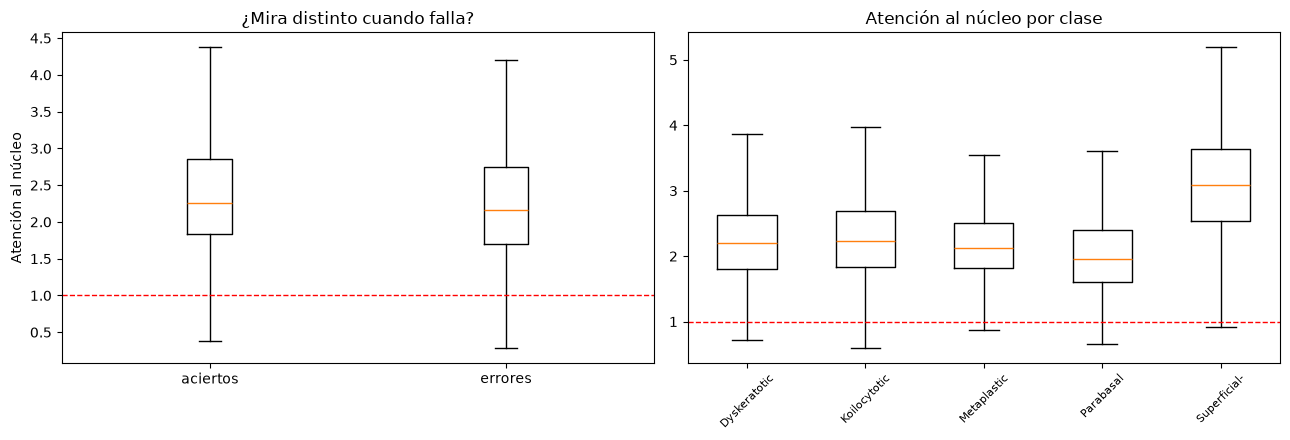

In [36]:
acierta = (pred_p5 == Y)
val = ~np.isnan(ATEN_NUC)
a, b = ATEN_NUC[val & acierta], ATEN_NUC[val & ~acierta]
u, p = mannwhitneyu(a, b)

print(f"Aciertos (n={len(a)}): {np.median(a):.2f} | errores (n={len(b)}): {np.median(b):.2f}")
print(f"p = {p:.2e} ->", "hay diferencia" if p < 0.05 else "no hay diferencia clara")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].boxplot([a, b], showfliers=False)
axes[0].set_xticks([1, 2]); axes[0].set_xticklabels(["aciertos", "errores"])
axes[0].axhline(1, color="r", ls="--", lw=1)
axes[0].set_ylabel("Atención al núcleo"); axes[0].set_title("¿Mira distinto cuando falla?")
axes[1].boxplot([ATEN_NUC[val & (df["clase"].values == c)] for c in CLASES], showfliers=False)
axes[1].set_xticks(range(1, len(CLASES) + 1))
axes[1].set_xticklabels([c[:12] for c in CLASES], rotation=45, fontsize=8)
axes[1].axhline(1, color="r", ls="--", lw=1)
axes[1].set_title("Atención al núcleo por clase")
plt.tight_layout(); plt.show()

**Interpretación: la red sí mira el núcleo.**

Atención al núcleo **2.39**, al citoplasma 1.47, al fondo 0.36. Es decir, concentra en el núcleo casi
dos veces y media más atención de la que le correspondería por su tamaño, y prácticamente ignora el
fondo. Descarta la sospecha de que estuviera decidiendo por el contexto o por artefactos de la
imagen.

Junto con la parte 4, la historia queda completa y coherente: **la red mira el núcleo, pero lee su
color y su textura, no su forma**. Por eso tiene codificados la oscuridad y el contraste nuclear
(R² alrededor de 0.64) y no la redondez ni el alargamiento, y por eso darle descriptores de forma no
la ayuda.

**Sobre los errores, cuidado con la lectura.** Los aciertos tienen atención 2.26 y los errores 2.16,
con p = 0.045. Formalmente hay diferencia, pero la magnitud es mínima y el valor de p está pegado al
umbral: con 3915 aciertos contra 109 errores, una diferencia de una décima alcanza significancia sin
significar gran cosa. La conclusión honesta es que **mirar el sitio equivocado no explica los
errores**; el modelo falla mirando aproximadamente donde debe.

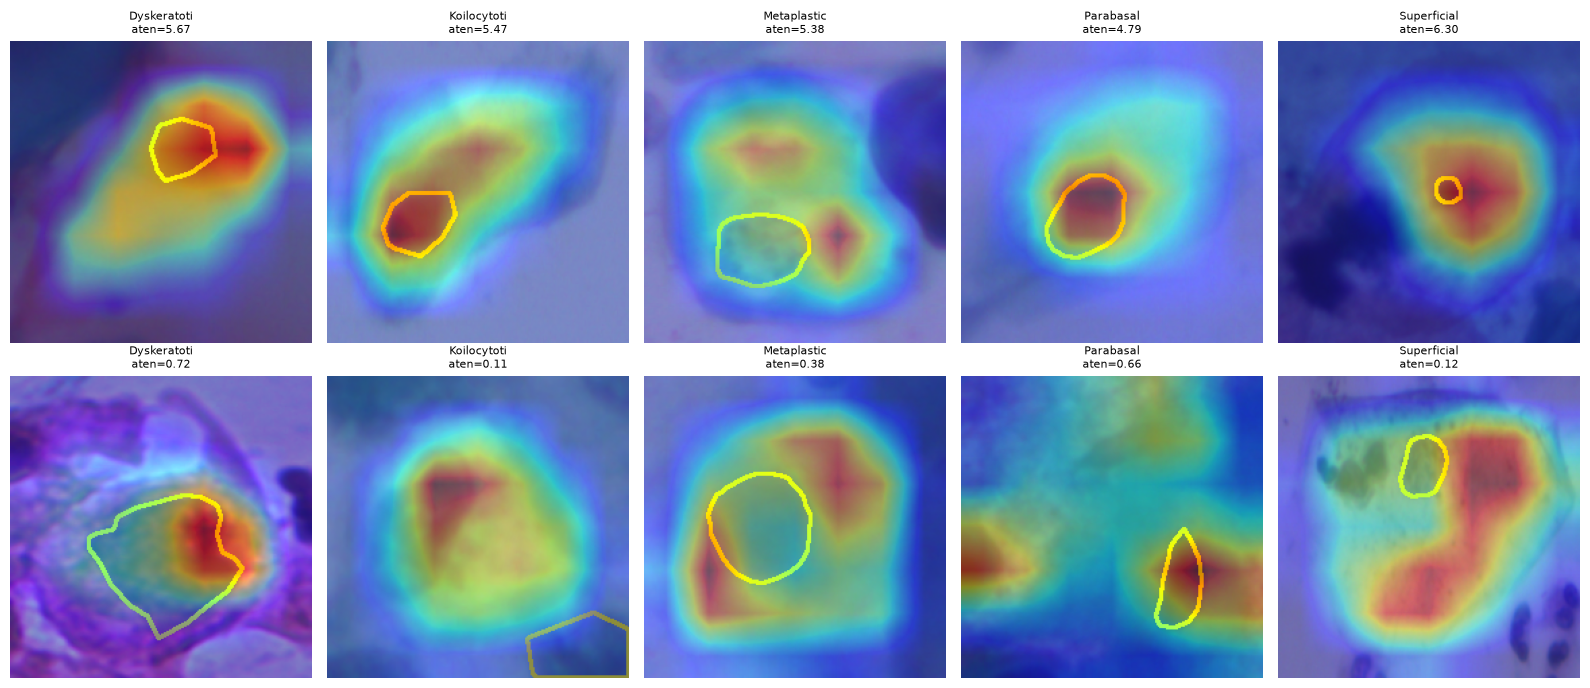

In [37]:
# Ejemplos visuales: el que mas mira el nucleo y el que menos, por clase
ejemplos = []
for c in CLASES:
    cand = np.where((df["clase"].values == c) & val)[0]
    ejemplos += [cand[np.argmax(ATEN_NUC[cand])], cand[np.argmin(ATEN_NUC[cand])]]

base, cabeza = cargar(0)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for j, p in enumerate(ejemplos):
    x = tf_eval(torch.from_numpy(CACHE[p]).permute(2, 0, 1)).unsqueeze(0).to(DEV)
    cam, _ = mapas_calor(base, cabeza, x)
    cam = cam[0] / (cam[0].max() + 1e-8)
    m_nuc, _ = mascaras(p)
    cont, _ = cv2.findContours(m_nuc, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    vis = CACHE[p].copy(); cv2.drawContours(vis, cont, -1, (255, 255, 0), 2)

    ax = axes[j % 2, j // 2]
    ax.imshow(vis); ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.set_title(f"{df.loc[p,'clase'][:11]}\naten={ATEN_NUC[p]:.2f}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()
del base, cabeza; torch.cuda.empty_cache()

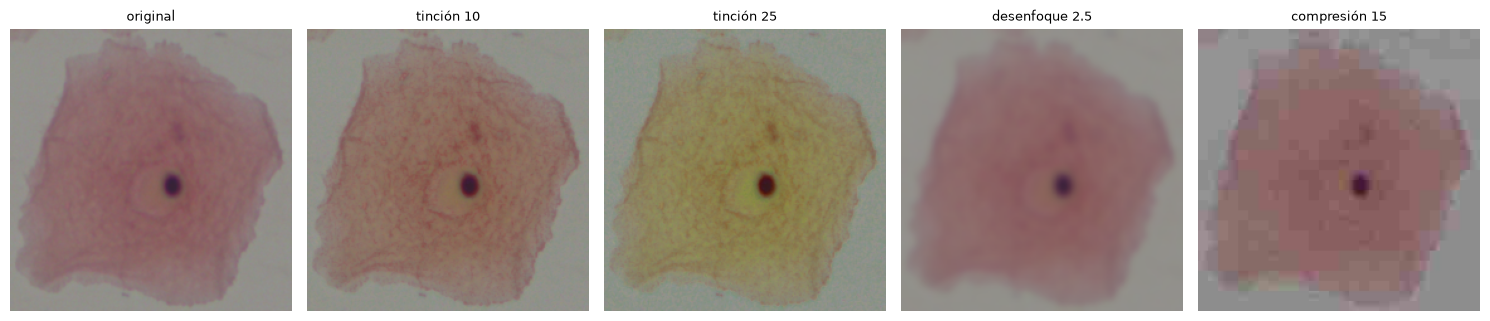

In [38]:
def perturbar(img, tipo, nivel):
    if tipo == "tinción":
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.int16)
        hsv[..., 0] = (hsv[..., 0] + nivel) % 180                    # corre el tono
        hsv[..., 1] = np.clip(hsv[..., 1] * (1 + nivel / 60), 0, 255)
        return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    if tipo == "desenfoque":
        return cv2.GaussianBlur(img, (0, 0), sigmaX=nivel)
    if tipo == "compresión":
        _, buf = cv2.imencode(".jpg", img[:, :, ::-1],
                              [int(cv2.IMWRITE_JPEG_QUALITY), nivel])
        return cv2.imdecode(buf, cv2.IMREAD_COLOR)[:, :, ::-1]
    return img


class CelulasPerturbadas(Dataset):
    def __init__(self, posiciones, tipo, nivel):
        self.pos = np.asarray(posiciones); self.tipo = tipo; self.nivel = nivel

    def __len__(self):
        return len(self.pos)

    def __getitem__(self, i):
        p = self.pos[i]
        img = perturbar(CACHE[p], self.tipo, self.nivel)
        return tf_eval(torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1)), Y[p], p


fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, (t, n) in zip(axes, [(None, 0), ("tinción", 10), ("tinción", 25),
                             ("desenfoque", 2.5), ("compresión", 15)]):
    ax.imshow(CACHE[0] if t is None else perturbar(CACHE[0], t, n))
    ax.set_title("original" if t is None else f"{t} {n}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [39]:
CONDICIONES = [("original", None, 0),
               ("tinción", "tinción", 8), ("tinción", "tinción", 16), ("tinción", "tinción", 25),
               ("desenfoque", "desenfoque", 1.0), ("desenfoque", "desenfoque", 2.0),
               ("desenfoque", "desenfoque", 3.0),
               ("compresión", "compresión", 50), ("compresión", "compresión", 25),
               ("compresión", "compresión", 10)]

filas = []
for etiqueta, tipo, nivel in CONDICIONES:
    pred = np.full(len(df), -1)
    for k in range(5):
        base, cabeza = cargar(k)
        te = np.where(df["fold_lamina"].values == k)[0]
        dl = DataLoader(CelulasPerturbadas(te, tipo, nivel), batch_size=128, num_workers=NUM_WORKERS)
        with torch.no_grad():
            for x, y, pos in dl:
                with torch.amp.autocast(DEV):
                    s = cabeza(base(x.to(DEV)))
                pred[pos.numpy()] = s.argmax(1).cpu().numpy()
        del base, cabeza; torch.cuda.empty_cache()
    f1 = f1_score(Y, pred, average="macro")
    filas.append({"perturbación": etiqueta, "nivel": nivel, "macro_f1": f1})
    print(f"  {etiqueta:12s} nivel {nivel:5} -> F1 {f1:.4f}")

rob = pd.DataFrame(filas)
rob["caída_%"] = ((rob.loc[0, "macro_f1"] - rob["macro_f1"]) / rob.loc[0, "macro_f1"] * 100).round(2)
rob.to_csv(f"{DEST}/robustez_fase5.csv", index=False)
rob

  original     nivel     0 -> F1 0.9731
  tinción      nivel     8 -> F1 0.9531
  tinción      nivel    16 -> F1 0.8981
  tinción      nivel    25 -> F1 0.7766
  desenfoque   nivel   1.0 -> F1 0.9220
  desenfoque   nivel   2.0 -> F1 0.7336
  desenfoque   nivel   3.0 -> F1 0.5845
  compresión   nivel    50 -> F1 0.8980
  compresión   nivel    25 -> F1 0.8650
  compresión   nivel    10 -> F1 0.6680


,perturbación,nivel,macro_f1,caída_%
0,original,0.0,0.973078,0.00
1,tinción,8.0,0.953065,2.06
2,tinción,16.0,0.898106,7.70
3,tinción,25.0,0.776620,20.19
4,desenfoque,1.0,0.921997,5.25
5,desenfoque,2.0,0.733612,24.61
6,desenfoque,3.0,0.584465,39.94
7,compresión,50.0,0.897971,7.72
8,compresión,25.0,0.865047,11.10
9,compresión,10.0,0.667956,31.36


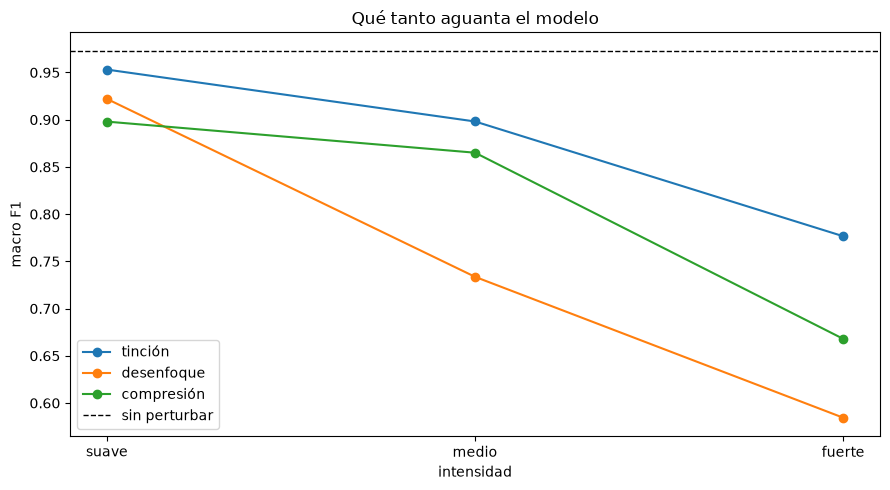

In [40]:
fig, ax = plt.subplots(figsize=(9, 5))
for tipo in ["tinción", "desenfoque", "compresión"]:
    sub = rob[rob["perturbación"] == tipo]
    ax.plot([1, 2, 3], sub["macro_f1"], "o-", label=tipo)
ax.axhline(rob.loc[0, "macro_f1"], color="k", ls="--", lw=1, label="sin perturbar")
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["suave", "medio", "fuerte"])
ax.set_xlabel("intensidad"); ax.set_ylabel("macro F1")
ax.set_title("Qué tanto aguanta el modelo"); ax.legend()
plt.tight_layout(); plt.show()

In [41]:
# ¿Cuando el modelo empeora, es porque dejo de mirar el nucleo?
ATEN_PERT = np.full(len(df), np.nan)
for k in range(5):
    base, cabeza = cargar(k)
    te = np.where(df["fold_lamina"].values == k)[0]
    dl = DataLoader(CelulasPerturbadas(te, "tinción", 25), batch_size=32, num_workers=NUM_WORKERS)
    for x, y, pos in dl:
        cams, _ = mapas_calor(base, cabeza, x.to(DEV))
        for j, p in enumerate(pos.numpy()):
            cam = cams[j]
            if cam.sum() <= 0:
                continue
            m_nuc, _ = mascaras(p)
            a = m_nuc.mean()
            if a > 0:
                ATEN_PERT[p] = (cam[m_nuc == 1].sum() / cam.sum()) / a
    del base, cabeza; torch.cuda.empty_cache()
    print(f"  pliegue {k} listo")

ok = ~np.isnan(ATEN_NUC) & ~np.isnan(ATEN_PERT)
print(f"\nAtención al núcleo original:  {ATEN_NUC[ok].mean():.3f}")
print(f"Atención con tinción alterada: {ATEN_PERT[ok].mean():.3f}")
print(f"Cambio: {ATEN_PERT[ok].mean() - ATEN_NUC[ok].mean():+.3f}")

sal = df[["stem", "clase", "lamina", "fold_lamina"]].copy()
sal["pred"] = pred_p5
sal["aten_nucleo"] = ATEN_NUC; sal["aten_citoplasma"] = ATEN_CIT
sal["aten_fondo"] = ATEN_FON; sal["aten_nucleo_perturbado"] = ATEN_PERT
sal.to_csv(f"{DEST}/atencion_fase5.csv", index=False)
print("Guardado")

  pliegue 0 listo
  pliegue 1 listo
  pliegue 2 listo
  pliegue 3 listo
  pliegue 4 listo

Atención al núcleo original:  2.394
Atención con tinción alterada: 2.706
Cambio: +0.312
Guardado


---
# Conclusiones

**1. La fuga por procedencia es real y está subestimada en cómo se reporta.** Repartir al azar deja
al 91.8% de las células de examen con una hermana en el entrenamiento, esconde alrededor de 1 de
cada 4 errores y reduce a menos de la mitad la variabilidad aparente. La cifra que suele publicarse
no solo es alta, además parece más precisa de lo que es. La magnitud del efecto varía entre corridas
(entre un cuarto y un 40% de los errores), pero su dirección y su significancia no.

**2. Aun así, estos modelos aprenden de verdad.** Con evaluación honesta el acierto sigue en 0.973.
Lo que se infla no es la capacidad del modelo sino la confianza en la medición. Conviene decirlo con
esa precisión y no exagerar en la dirección contraria.

**3. Añadir medidas morfológicas no aporta: perjudica.** Ni las 26 completas ni el tamaño original
que creíamos perdido. Y se demuestra con una comparación en la que solo cambia una variable, que es
justamente lo que falta en los trabajos que presentan esa fusión como novedad.

**4. La red mira el núcleo, pero lo lee por color, no por forma.** Concentra 2.4 veces más atención
de la que le tocaría por tamaño, y tiene codificados su oscuridad, contraste y textura, pero no su
redondez, alargamiento ni solidez. Eso explica por qué los descriptores de forma no ayudan. Además,
ajustarse a la tarea empobrece su representación morfológica frente a la red genérica, en las doce
medidas probadas.

**5. Es frágil, y falla de una forma reveladora.** Un desenfoque suave le cuesta 5 puntos y uno
moderado un cuarto del rendimiento; la compresión fuerte, un tercio; un cambio de tinción marcado,
un quinto. Lo llamativo es cómo falla: al alterar la tinción, la atención al núcleo **sube** de 2.39
a 2.71 mientras el acierto cae 20 puntos. **Sigue mirando el sitio correcto y lee la señal
equivocada**, que es exactamente lo que cabe esperar de un modelo que se apoya en el color del
núcleo. Y encaja con que el desenfoque, que destruye la textura, sea la perturbación más dañina.

**Implicación práctica.** Cualquier despliegue fuera del laboratorio de origen necesitaría
normalización de tinción y control de enfoque, y ambas cosas son más urgentes que ganar décimas de
acierto en el conjunto propio.

## Limitaciones

- **No sabemos de qué paciente viene cada lámina.** Las 966 láminas podrían venir de bastantes menos
  pacientes, así que puede quedar contaminación residual que no podemos eliminar por falta de ese
  dato. La lámina es la agrupación más fina disponible.
- **Una sola semilla.** La dirección de los efectos es estable, pero la magnitud de la fuga varía
  entre corridas. Promediar varias semillas daría una estimación más firme.
- **Una sola arquitectura.** Los resultados podrían diferir con otras redes, aunque el efecto del
  reparto no debería depender del modelo.
- **Un error de anotación** detectado en el dataset (un núcleo más grande que su propia célula).
- **Las perturbaciones son simuladas.** Aproximan las condiciones de otro laboratorio, no las
  reemplazan.

## Qué se podría hacer después

- Repetir la comparación de repartos con varias semillas y otras arquitecturas, para acotar la
  magnitud del efecto.
- Probar normalización de tinción antes de entrenar y volver a medir la caída: es la vía más directa
  para atacar la fragilidad encontrada.
- Trabajar sobre las láminas completas en vez de las células recortadas, que es la tarea que de
  verdad se parece al tamizaje real.
- Atacar específicamente la confusión entre koilocitótica y disqueratótica, que concentra la mayoría
  de los errores que quedan.